# Lecture 7: Autoregressive Rollout Models

A rollout applies a one-step model to its own output. In this notebook we

1. **predict all fields**: predict θ, u and v so the model no longer needs velocity from the simulation,
2. **train for rollout** with the pushforward trick and with noise injection, and compare with one-step training.

To keep training short, we average BubbleML from 128 × 128 to 64 × 64 and use SmallCNN.

In [1]:
import os
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)
torch.manual_seed(0)

DATA_DIR = "../data/bubbleml"
FILE = "bubbleml2_Twall106_128.npz"
URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/bubbleml/"
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(os.path.join(DATA_DIR, FILE)):
    print("downloading", FILE)
    urllib.request.urlretrieve(URL + FILE, os.path.join(DATA_DIR, FILE))

# temperature colormap from Lecture 1 (https://github.com/therml-ai/boiling-viz), for theta in [0, 1]
temp_cmap = LinearSegmentedColormap.from_list("temp_green", list(zip(
    [0.0, 0.02, 0.04, 0.06, 0.08, 0.1, 0.134, 0.167, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    ["#0000FF", "#0443FF", "#0E7AFF", "#16B4FF", "#1FF1FF", "#21FFD3", "#22FF9B", "#22FF67", "#22FF15", "#29FF06",
     "#45FF07", "#6DFF08", "#9EFF09", "#D4FF0A", "#FEF30A", "#FEB709", "#FD7D08", "#FC4908", "#FC1407", "#FB0007"])))

Using device: mps


### The data

BubbleML_2, subcooled pool boiling of FC-72 with a 106 °C heater (the Lecture 6 file), averaged to 64 × 64 (cell size 0.25).
Frames are 0.2 nondimensional time units apart. Channels: $\theta = (T - 50\,°\mathrm{C})/(106\,°\mathrm{C} - 50\,°\mathrm{C})$ and the velocity $u, v$.
The first 600 frames are for training, the last 201 for testing.

In [2]:
d = np.load(os.path.join(DATA_DIR, FILE))
data = np.stack([d["temperature"], d["velx"], d["vely"]], axis=1).astype(np.float32)   # [frames, 3, 128, 128]
data = data.reshape(len(data), 3, 64, 2, 64, 2).mean(axis=(3, 5))                       # 2 x 2 average -> 64 x 64
train_np, test_np = data[:600], data[600:]
mu, sd = train_np.mean(axis=(0, 2, 3)), train_np.std(axis=(0, 2, 3))
du = train_np[1:] - train_np[:-1]
mu_du, sd_du = du.mean(axis=(0, 2, 3)), du.std(axis=(0, 2, 3))
train_t = torch.from_numpy(train_np)
print("train:", train_np.shape, "  test:", test_np.shape)

train: (600, 3, 64, 64)   test: (201, 3, 64, 64)


---
## Part 1: Predict all fields

`Surrogate` standardizes the inputs and predicts the standardized change of the first `cout` channels (Lecture 4).
With `cout = 1` it predicts θ only, and a rollout needs $u, v$ from the simulation. With `cout = 3` it predicts all three fields, and the rollout needs nothing from the simulation.

In [3]:
def smallcnn_body(cin=3, hidden=32, cout=1):
    c = lambda i, o: nn.Conv2d(i, o, 3, padding=1)
    return nn.Sequential(c(cin, hidden), nn.GELU(), c(hidden, hidden), nn.GELU(), c(hidden, hidden), nn.GELU(), c(hidden, cout))

class Surrogate(nn.Module):
    def __init__(self, cout):
        super().__init__()
        self.net, self.cout = smallcnn_body(cout=cout), cout
        self.register_buffer("mu", torch.tensor(mu).view(1, 3, 1, 1))
        self.register_buffer("sd", torch.tensor(sd).view(1, 3, 1, 1))
        self.register_buffer("mu_du", torch.tensor(mu_du[:cout]).view(1, cout, 1, 1))
        self.register_buffer("sd_du", torch.tensor(sd_du[:cout]).view(1, cout, 1, 1))

    def increment(self, x):                     # standardized change, the network's output
        return self.net((x - self.mu) / self.sd)

    def forward(self, x):                       # next state of the first cout channels
        return x[:, :self.cout] + self.mu_du + self.sd_du * self.increment(x)

STEPS = 600

def train(cout, mode="one-step", K=3, sigma=0.0, steps=STEPS, batch=16, seed=0):
    # mode: "one-step", "noise" (add noise of size sigma to standardized inputs), "pushforward" (K - 1 steps without gradient)
    torch.manual_seed(seed); g = np.random.default_rng(seed)
    model = Surrogate(cout).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    t0 = time.time()
    for step in range(steps):
        k = g.integers(1, K + 1) if mode == "pushforward" else 1        # steps from input to target
        i = g.integers(0, len(train_t) - k, batch)
        x = train_t[i].to(device)
        y = train_t[i + k].to(device)
        if mode == "pushforward" and k > 1:
            with torch.no_grad():                                        # sg[...]: no gradient through these steps
                for _ in range(k - 1):
                    x = model(x)
        if mode == "noise":
            x = x + sigma * model.sd * torch.randn_like(x)
        target = (y[:, :cout] - x[:, :cout] - model.mu_du) / model.sd_du
        loss = F.mse_loss(model.increment(x), target)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % 200 == 0:
            print(f"  step {step:4d}  loss {loss.item():.3f}  ({time.time() - t0:.0f} s)")
    return model.eval()

@torch.no_grad()
def rollout(model, steps=200):
    # returns theta at every step; velocity from the simulation if the model predicts theta only
    s = torch.from_numpy(test_np[:1]).to(device); out = [test_np[0, 0]]
    for n in range(steps):
        p = model(s)
        s = p if model.cout == 3 else torch.cat([p, torch.from_numpy(test_np[n + 1:n + 2, 1:]).to(device)], dim=1)
        out.append(s[0, 0].cpu().numpy())
    return np.stack(out)

def rel_err(roll):
    t = test_np[:len(roll), 0]
    return np.linalg.norm((roll - t).reshape(len(roll), -1), axis=1) / np.linalg.norm(t.reshape(len(roll), -1), axis=1)

velocity given (predicts theta)
  step    0  loss 0.990  (1 s)
  step  200  loss 0.274  (4 s)
  step  400  loss 0.249  (7 s)
velocity predicted (predicts theta, u, v)
  step    0  loss 0.982  (0 s)
  step  200  loss 0.420  (3 s)
  step  400  loss 0.405  (6 s)


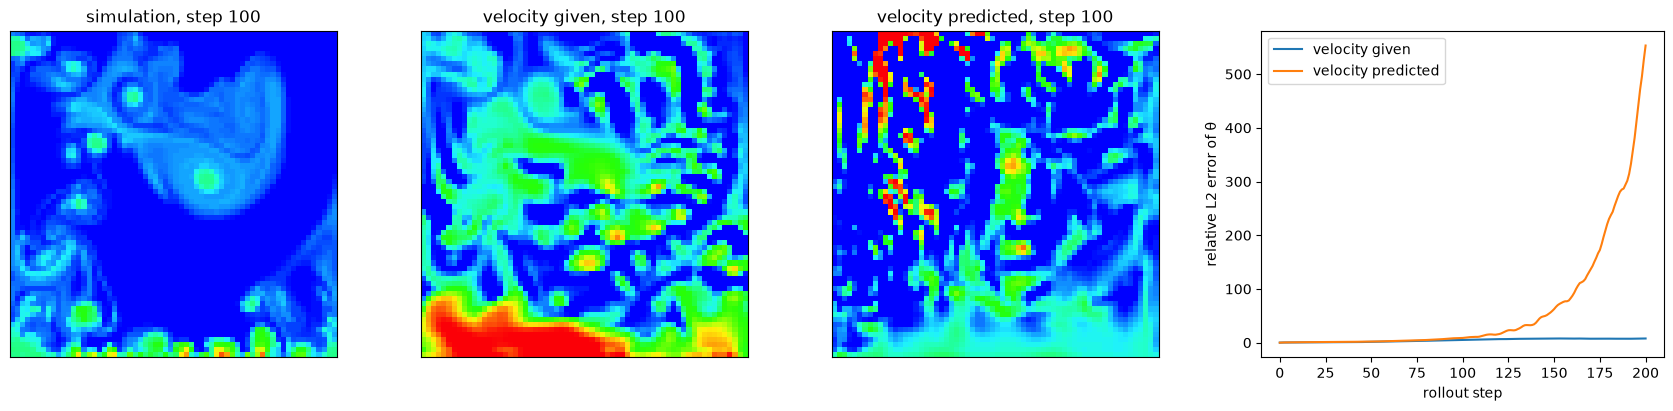

In [4]:
print("velocity given (predicts theta)"); m_given = train(cout=1)
print("velocity predicted (predicts theta, u, v)"); m_pred = train(cout=3)
rolls = {"velocity given": rollout(m_given), "velocity predicted": rollout(m_pred)}

fig, ax = plt.subplots(1, 4, figsize=(17, 4), layout="constrained")
n = 100
for a, (f, t) in zip(ax[:3], [(test_np[n, 0], "simulation"), (rolls["velocity given"][n], "velocity given"), (rolls["velocity predicted"][n], "velocity predicted")]):
    a.imshow(f, cmap=temp_cmap, vmin=0, vmax=1, origin="lower"); a.set_title(f"{t}, step {n}"); a.set_xticks([]); a.set_yticks([])
for name, r in rolls.items():
    ax[3].plot(rel_err(r), label=name)
ax[3].set_xlabel("rollout step"); ax[3].set_ylabel("relative L2 error of θ"); ax[3].legend()
plt.show()

**What to observe**

* Compare the two error curves. One model gets the true velocity at every step; the other has to predict it.
* Look at the bubble interfaces at step 100. Are they sharp or smeared? Is the plume in the right place?
* Pressure is not an input, so the state is incomplete. Exercise 2 adds a history of frames.

---
## Part 2: Train for rollout

Three models that predict θ, u and v, with the same number of optimizer steps:

* **one-step**: the Part 1 model,
* **noise injection**: add Gaussian noise of size σ (in standardized units) to the input,
* **pushforward**: draw $k \in \{1, \dots, K\}$, apply the model $k - 1$ times without gradient, then train one step against the true state $k$ frames ahead.

noise injection
  step    0  loss 1.009  (0 s)
  step  200  loss 0.441  (2 s)
  step  400  loss 0.425  (6 s)
pushforward
  step    0  loss 2.939  (0 s)
  step  200  loss 0.518  (3 s)
  step  400  loss 1.107  (6 s)


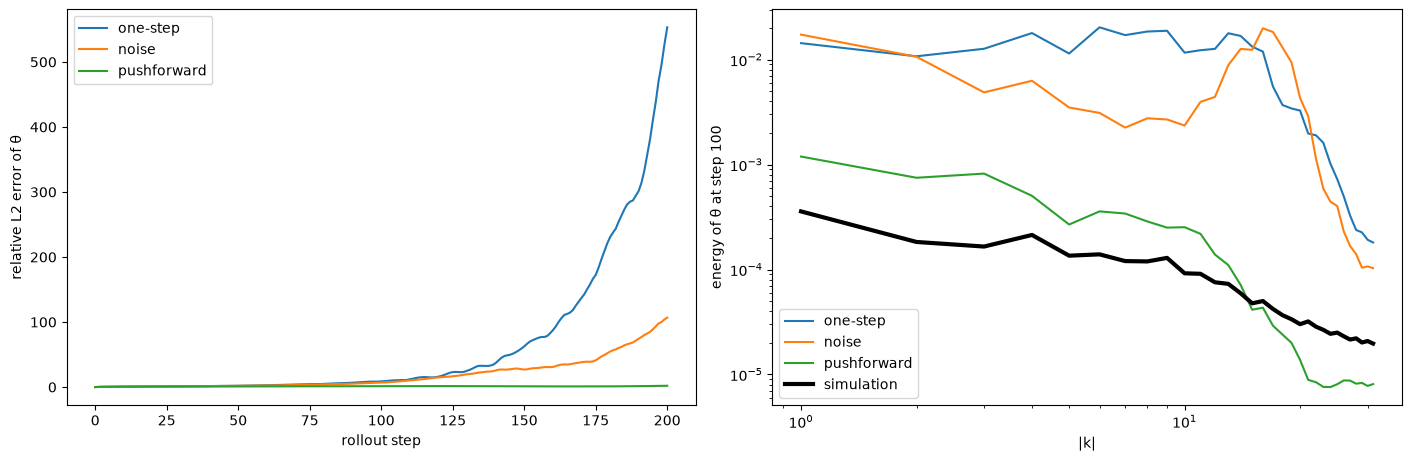

In [5]:
print("noise injection"); m_noise = train(cout=3, mode="noise", sigma=0.05)
print("pushforward");     m_push = train(cout=3, mode="pushforward", K=3)
rolls.update({"noise": rollout(m_noise), "pushforward": rollout(m_push)})

def radial_spectrum(f):
    n = f.shape[-1]; U = np.fft.fft2(f - f.mean(axis=(-2, -1), keepdims=True)) / n**2
    P = np.abs(U) ** 2
    if P.ndim == 3: P = P.mean(0)
    kk = np.sqrt((np.fft.fftfreq(n) * n)[:, None] ** 2 + (np.fft.fftfreq(n) * n)[None, :] ** 2)
    return np.arange(1, n // 2), np.array([P[(kk >= a - 0.5) & (kk < a + 0.5)].sum() for a in range(1, n // 2)])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")
for name in ["velocity predicted", "noise", "pushforward"]:
    ax[0].plot(rel_err(rolls[name]), label=name if name != "velocity predicted" else "one-step")
    ax[1].loglog(*radial_spectrum(rolls[name][100]), label=name if name != "velocity predicted" else "one-step")
ax[1].loglog(*radial_spectrum(test_np[:, 0]), "k", lw=3, label="simulation")
ax[0].set_xlabel("rollout step"); ax[0].set_ylabel("relative L2 error of θ"); ax[0].legend()
ax[1].set_xlabel("|k|"); ax[1].set_ylabel("energy of θ at step 100"); ax[1].legend()
plt.show()

**What to observe**

* Compare the error curves early (one-step accuracy) and late (drift). Training for rollout can cost a little one-step accuracy at a fixed compute budget.
* Compare the spectra at step 100: which model keeps the most small-scale energy?

---
## Exercises

1. **Temporal bundling.** Change `smallcnn_body` to output the next K = 4 frames of θ, u, v (12 channels) and rollout in blocks of 4. Compare error at the same physical time.
2. **History.** Input the two most recent frames (6 channels). Does the rollout improve?
3. **Unrolled training.** Replace the `torch.no_grad()` block in `train` by an unrolled loss summed over the K steps. Compare time per step and memory with pushforward.
4. **Noise scale.** Sweep `sigma` over 0.01, 0.05, 0.2. Plot one-step error and error at step 100 against σ.

In [6]:
# Exercise 1 starter
def bundled_body(cin=3, hidden=32, K=4):
    # TODO: like smallcnn_body, but output 3 * K channels: the changes of theta, u, v for the next K frames
    raise NotImplementedError